EXERCICE : RNN qui génère du texte (Victor Hugo)


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

In [12]:
with open('victor_hugo/victor_hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip() != '']
print(f"Exemple de texte: {texts[0]}")

Exemple de texte: Mes vers fuiraient


In [13]:
#  Tokenizer — transformer les mots en nombres

vocab_size = 1000
window_size = 3

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences =tokenizer.texts_to_sequences(texts)

In [14]:
X = []
y = []
for seq in sequences:
    for i in range(1, len(seq)):
        start_index = max(0, i - window_size)
        X.append(seq[start_index:i])
        y.append(seq[i])
X = pad_sequences(X, maxlen=window_size, padding='pre')
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (11541, 3), y shape: (11541,)


In [15]:
embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    SimpleRNN(32),
    Dense(vocab_size, activation='softmax')
])

In [16]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [17]:
#Entrainer
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.0351 - loss: 6.1485
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0389 - loss: 5.8236
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0452 - loss: 5.7092
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0522 - loss: 5.6060
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0603 - loss: 5.5169
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0646 - loss: 5.4384
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0697 - loss: 5.3661
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0751 - loss: 5.2966
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0801 - loss: 5.2281
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0878 - loss: 5.1594
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0921 - loss: 5.0898
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

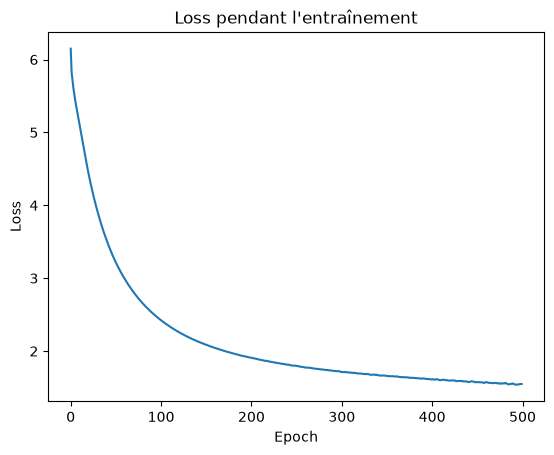

In [18]:
# Viualiser la loss 
plt.plot(history.history['loss'])
plt.title("Loss pendant l'entraînement")
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [19]:
#Générer du texte  LA PARTIE MAGIQUE

def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')
        probs = model.predict(tokens, verbose=0)[0]

        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)
        word = tokenizer.index_word.get(index)
        if word is not None:
            text += ' ' + word
    return text

random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème poète de la mère qui sabine ce sont déjà flamme qui toutes les à son fit ce que leur rêve avec je veux sur ces j'ai femmes vous des crépuscule enfants chimère vivant vieux de qui et de dieu triste son burgrave écoutez des ailes qu'un hydre à vieux sans


In [20]:
from tensorflow.keras.layers import LSTM

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    LSTM(64),
    Dense(vocab_size, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
# On entraîne le LSTM avec les MÊMES données X, y que le SimpleRNN
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history_lstm = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0347 - loss: 6.1672
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0358 - loss: 5.8572
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0353 - loss: 5.7969
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0376 - loss: 5.7501
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0400 - loss: 5.7168
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0397 - loss: 5.6813
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0415 - loss: 5.6357
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0451 - loss: 5.5845
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0497 - loss: 5.5289
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0525 - loss: 5.4751
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0561 - loss: 5.4234
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

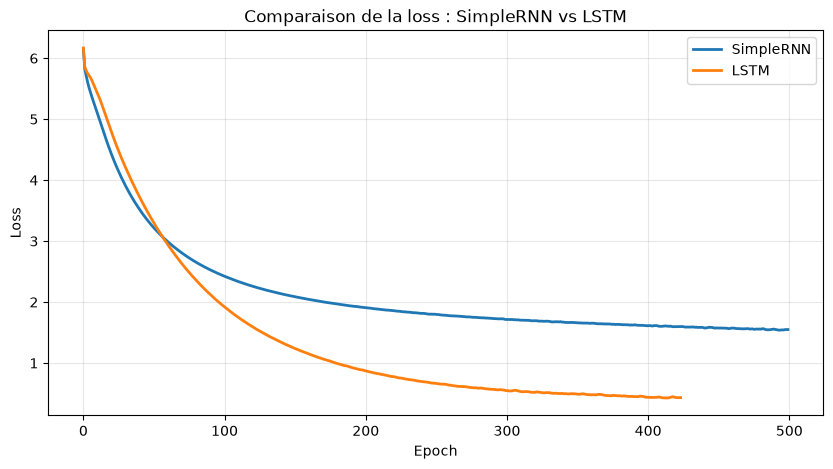

Loss finale SimpleRNN : 1.5488
Loss finale LSTM      : 0.4322


In [22]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='SimpleRNN', linewidth=2)
plt.plot(history_lstm.history['loss'], label='LSTM', linewidth=2)
plt.title("Comparaison de la loss : SimpleRNN vs LSTM")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Loss finale SimpleRNN : {history.history['loss'][-1]:.4f}")
print(f"Loss finale LSTM      : {history_lstm.history['loss'][-1]:.4f}")

In [23]:
random_text_lstm = generate_text("Poème", num_words=50, temperature=0.8)
print("Texte généré par le LSTM :\n")
print(random_text_lstm)

Texte généré par le LSTM :

Poème c'est à qui voyez j'étais et si se comme à nos pas faites le de poisson qui effroi dans cette forêt sourire la des ainsi avec les qui ils sont jamais par l'homme l'été une plein et tous dans le cercle fleur sur des bois ma meilleure pensée est elle


In [24]:
for temp in [0.5, 0.8, 1.2]:
    print(f"\n{'='*60}")
    print(f"TEMPÉRATURE = {temp}")
    print('='*60)
    print(generate_text("Poème", num_words=30, temperature=temp))


TEMPÉRATURE = 0.5
Poème que votre coeur qu'un point navire a jeannie de combattent sa du mur ni le bruit de pêcheur de et pour choses qui font de la fois toujours dans les

TEMPÉRATURE = 0.8
Poème à nos du ciel nos âmes parmi les rayons parmi les flammes avec des cris des chants des des voilà que de partout un d'un démon d'être – c'est tout

TEMPÉRATURE = 1.2
Poème dont les ailes aux des » je sur cette durandal un comme et une tu âpre a l'enfant colombe il y comme un chapelle c'est ses pas cela dort une
